<a href="https://colab.research.google.com/github/SuMiaRbyte/BERKLEY/blob/main/prompt_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

## Business Understanding

From a business perspective, the goal is to identify the key drivers of used car prices so that a used car dealership can make better decisions about which vehicles to stock and how to price them. Framed as a data problem, this is a **supervised learning regression task**: the target variable is `price`, and the predictors are vehicle attributes such as `year`, `odometer`, `manufacturer`, `condition`, `fuel`, `transmission`, `drive`, and `type`. We will clean and prepare the data, fit and compare regression models (for example, linear regression with regularization), and evaluate them on held-out data using RMSE and R². The fitted models' coefficients and feature importances will then be interpreted to determine which features most strongly influence price, and those findings will be translated into plain-language recommendations for the dealership.

In [5]:
# Core data handling
import numpy as np
import pandas as pd


In [6]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
# Preprocessing and pipelines
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [8]:
# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV


In [9]:
# Evaluation and interpretation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

In [10]:
# Display settings
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_style("whitegrid")

## Data Understanding

To get familiar with the dataset and identify quality issues, I will take the following steps:

1. **Load the data and inspect its size and structure.** Check the number of rows and columns, and preview the first few records with `head()`.
2. **Review column names and data types** with `info()` to confirm that numeric fields (`price`, `year`, `odometer`) are numeric and categorical fields are stored as text.
3. **Check for missing values.** Calculate the count and percentage of nulls in each column to see which features are too sparse to use, and which can be imputed.
4. **Check for duplicate records**, including repeated VINs.
5. **Summarize numeric features** with `describe()` and look for impossible or extreme values, such as prices of $0, prices in the millions, very old model years, or implausible odometer readings.
6. **Examine categorical features.** Count unique values and the most frequent categories in columns like `manufacturer`, `condition`, `fuel`, `type`, and `state`, and look for inconsistent labels or very rare categories.
7. **Visualize distributions** of `price`, `year`, and `odometer` with histograms and boxplots to see skew and outliers.
8. **Explore relationships with price.** Use scatterplots, boxplots, and a correlation heatmap to see how price varies with age, mileage, manufacturer, condition, and vehicle type.
9. **Summarize the quality issues found** (missing data, outliers, duplicates, inconsistent entries) and decide how each will be handled in Data Preparation.

In [11]:
# 1. Load and inspect
df = pd.read_csv("data/vehicles.csv")
print(df.shape)
df.head()

(426880, 18)


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


In [12]:
# 2. Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         426880 non-null  object 
dtypes: f

In [13]:
# 3. Missing values
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": df.isnull().mean() * 100
}).sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
size,306361,71.77
cylinders,177678,41.62
condition,174104,40.79
VIN,161042,37.73
drive,130567,30.59
paint_color,130203,30.50
type,92858,21.75
manufacturer,17646,4.13
title_status,8242,1.93
model,5277,1.24


In [14]:
# 4. Duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate VINs:", df["VIN"].dropna().duplicated().sum())

Duplicate rows: 0
Duplicate VINs: 147592


In [15]:
# 5. Numeric summary
df[["price", "year", "odometer"]].describe()

,price,year,odometer
count,"426,880.00","425,675.00","422,480.00"
mean,"75,199.03","2,011.24","98,043.33"
std,"12,182,282.17",9.45,"213,881.50"
min,0.00,"1,900.00",0.00
25%,"5,900.00","2,008.00","37,704.00"
50%,"13,950.00","2,013.00","85,548.00"
75%,"26,485.75","2,017.00","133,542.50"
max,"3,736,928,711.00","2,022.00","10,000,000.00"


In [16]:
# 6. Categorical features
cat_cols = df.select_dtypes(include="object").columns.drop(["id", "VIN", "model", "region"], errors="ignore")
for col in cat_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts(dropna=False).head(8))


manufacturer: 42 unique values
manufacturer
ford         70985
chevrolet    55064
toyota       34202
honda        21269
nissan       19067
jeep         19014
ram          18342
NaN          17646
Name: count, dtype: int64

condition: 6 unique values
condition
NaN          174104
good         121456
excellent    101467
like new      21178
fair           6769
new            1305
salvage         601
Name: count, dtype: int64

cylinders: 8 unique values
cylinders
NaN             177678
6 cylinders      94169
4 cylinders      77642
8 cylinders      72062
5 cylinders       1712
10 cylinders      1455
other             1298
3 cylinders        655
Name: count, dtype: int64

fuel: 5 unique values
fuel
gas         356209
other        30728
diesel       30062
hybrid        5170
NaN           3013
electric      1698
Name: count, dtype: int64

title_status: 6 unique values
title_status
clean         405117
NaN             8242
rebuilt         7219
salvage         3868
lien            1422
missing 

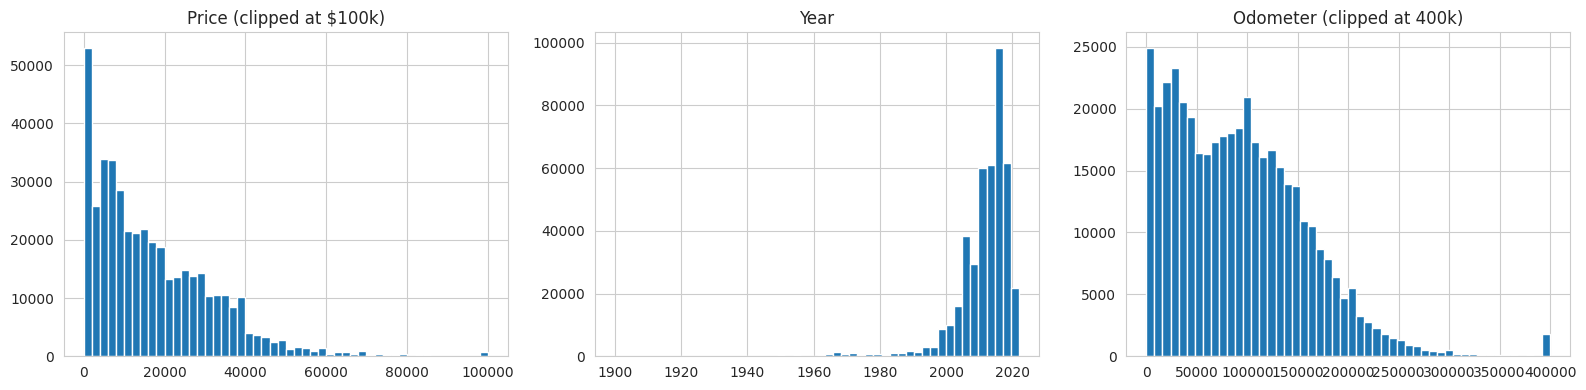

In [18]:
# 7. Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["price"].clip(upper=100000).hist(bins=50, ax=axes[0]); axes[0].set_title("Price (clipped at $100k)")
df["year"].dropna().hist(bins=50, ax=axes[1]); axes[1].set_title("Year")
df["odometer"].clip(upper=400000).hist(bins=50, ax=axes[2]); axes[2].set_title("Odometer (clipped at 400k)")
plt.tight_layout(); plt.show()

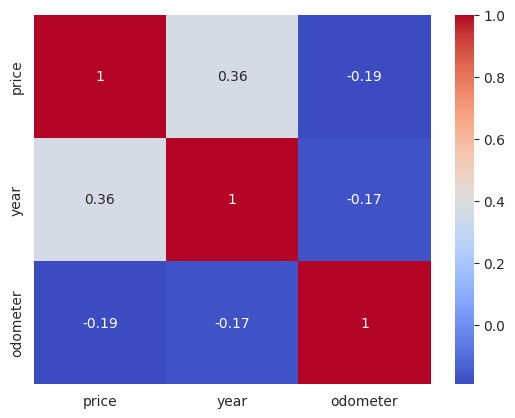

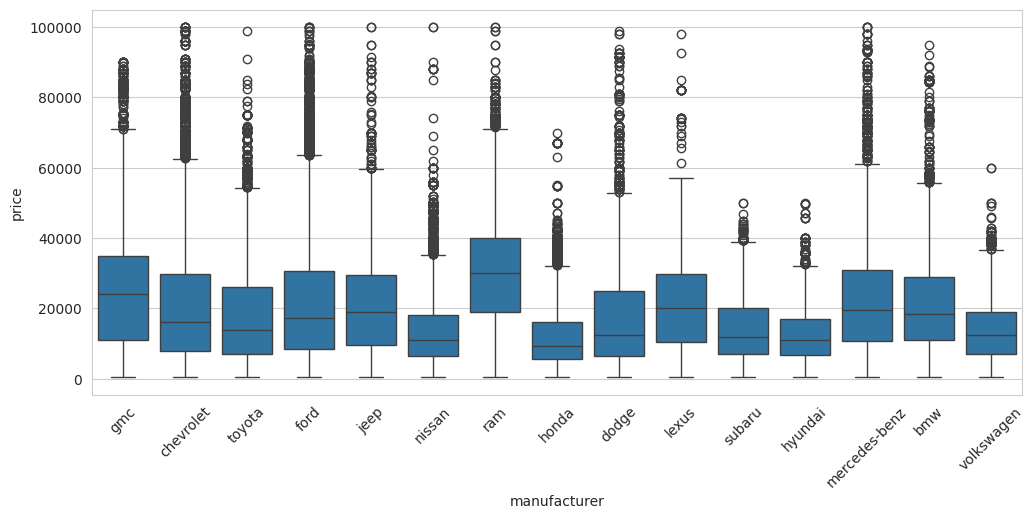

In [19]:
# 8. Relationships with price (using a reasonable price range for readability)
plot_df = df[(df["price"] > 500) & (df["price"] < 100000)]

sns.heatmap(plot_df[["price", "year", "odometer"]].corr(), annot=True, cmap="coolwarm")
plt.show()

top_mfr = plot_df["manufacturer"].value_counts().head(15).index
plt.figure(figsize=(12, 5))
sns.boxplot(data=plot_df[plot_df["manufacturer"].isin(top_mfr)], x="manufacturer", y="price")
plt.xticks(rotation=45); plt.show()

## Data Preparation

Based on the issues found in Data Understanding, I will: (1) remove duplicates and unusable columns, (2) filter unrealistic prices, years, and odometer readings, (3) engineer new features (vehicle age, number of cylinders), (4) log-transform the skewed target `price`, and (5) build an sklearn preprocessing pipeline that imputes missing values, scales numeric features, and one-hot encodes categorical features.

In [20]:
# 1. Remove duplicates and unusable columns
df_clean = df.drop_duplicates().copy()
df_clean = df_clean.drop(columns=["id", "VIN", "region", "size", "model"])
print(df_clean.shape)

(426880, 13)


In [21]:
# 2. Remove unrealistic values
df_clean = df_clean.dropna(subset=["price", "year", "odometer"])   # only ~1% missing
df_clean = df_clean[(df_clean["price"].between(500, 100000))]
df_clean = df_clean[(df_clean["year"] >= 1990)]
df_clean = df_clean[(df_clean["odometer"].between(100, 300000))]
print(df_clean.shape)

(363049, 13)


In [22]:
# 3. Feature engineering
ref_year = df_clean["year"].max()
df_clean["age"] = ref_year - df_clean["year"]

# "6 cylinders" -> 6 ; "other" / missing -> NaN (imputed later)
df_clean["cylinders"] = pd.to_numeric(
    df_clean["cylinders"].str.extract(r"(\d+)")[0], errors="coerce"
)

df_clean = df_clean.drop(columns=["year"])   # age replaces it

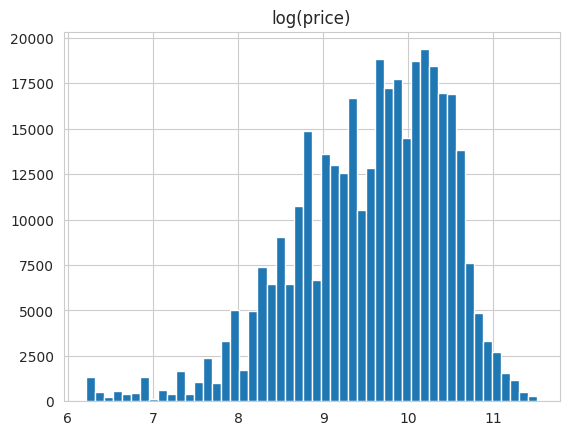

In [23]:
# 4. Target transformation: price is right-skewed, so use log(price)
df_clean["log_price"] = np.log1p(df_clean["price"])
df_clean["log_price"].hist(bins=50)
plt.title("log(price)"); plt.show()

In [24]:
# 5. Define features and target, then split
X = df_clean.drop(columns=["price", "log_price"])
y = df_clean["log_price"]

num_cols = ["age", "odometer", "cylinders"]
cat_cols = X.select_dtypes(include="object").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
# 6. Preprocessing pipeline (fit on training data only to avoid leakage)
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=100))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

## Modeling

I will compare several regression models predicting log(price): Linear Regression (baseline), Ridge, and Lasso. Each model sits in a pipeline with the preprocessing from the previous step. Hyperparameters are tuned with 5-fold cross-validation on the training set only, and the test set is used once at the end for final comparison. Errors are converted back to dollars so they are easy to interpret.

In [26]:
# Helper: score a fitted model on the test set, in dollars
def evaluate(name, model):
    pred_log = model.predict(X_test)
    pred = np.expm1(pred_log)
    actual = np.expm1(y_test)
    return {
        "model": name,
        "R2 (log price)": r2_score(y_test, pred_log),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
        "MAE ($)": mean_absolute_error(actual, pred),
    }

results = []

In [27]:
# 1. Baseline: Linear Regression
lin_pipe = Pipeline([("prep", preprocessor), ("model", LinearRegression())])

cv_rmse = -cross_val_score(lin_pipe, X_train, y_train, cv=5,
                           scoring="neg_root_mean_squared_error")
print("CV RMSE (log units):", cv_rmse.mean().round(4))

lin_pipe.fit(X_train, y_train)
results.append(evaluate("Linear Regression", lin_pipe))

CV RMSE (log units): 0.51


In [28]:
# 2. Ridge: tune the regularization strength (alpha)
ridge_pipe = Pipeline([("prep", preprocessor), ("model", Ridge())])
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": [0.1, 1, 10, 100]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
print("Best alpha:", ridge_grid.best_params_)
results.append(evaluate("Ridge", ridge_grid.best_estimator_))

Best alpha: {'model__alpha': 0.1}


In [29]:
# 3. Lasso: can shrink unhelpful features to exactly zero
lasso_pipe = Pipeline([("prep", preprocessor), ("model", Lasso(max_iter=5000))])
lasso_grid = GridSearchCV(
    lasso_pipe,
    param_grid={"model__alpha": [0.0001, 0.001, 0.01]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
lasso_grid.fit(X_train, y_train)
print("Best alpha:", lasso_grid.best_params_)
results.append(evaluate("Lasso", lasso_grid.best_estimator_))

Best alpha: {'model__alpha': 0.0001}


In [30]:
# 4. Compare all models
pd.DataFrame(results).sort_values("RMSE ($)").reset_index(drop=True)

,model,R2 (log price),RMSE ($),MAE ($)
0,Lasso,0.68,"7,997.42","4,982.83"
1,Ridge,0.68,"8,008.77","4,990.27"
2,Linear Regression,0.68,"8,009.05","4,990.13"


## Evaluation

In this phase I compare the models on held-out test data, check the best model's errors for patterns, and extract the features that drive price. I then decide whether earlier phases need revisiting or whether the findings are ready for the dealership.

In [31]:
comparison = pd.DataFrame(results).sort_values("RMSE ($)").reset_index(drop=True)
comparison

,model,R2 (log price),RMSE ($),MAE ($)
0,Lasso,0.68,"7,997.42","4,982.83"
1,Ridge,0.68,"8,008.77","4,990.27"
2,Linear Regression,0.68,"8,009.05","4,990.13"


In [39]:
# Pick the best model from the table above (change this line if a different model wins)
best_model = lasso_grid.best_estimator_      # or lasso_grid.best_estimator_ / rf_grid.best_estimator_

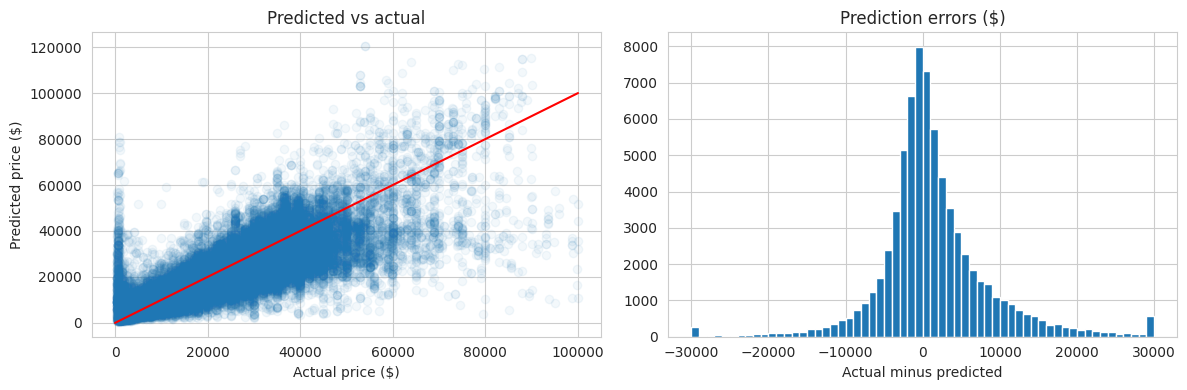

In [44]:
#Check the best model’s predictions
pred = np.expm1(best_model.predict(X_test))
actual = np.expm1(y_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Predicted vs actual: points should hug the diagonal
axes[0].scatter(actual, pred, alpha=0.05)
axes[0].plot([0, 100000], [0, 100000], color="red")
axes[0].set_xlabel("Actual price ($)"); axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Predicted vs actual")

# Residuals: should be centered on zero with no obvious pattern
residuals = actual - pred
axes[1].hist(residuals.clip(-30000, 30000), bins=60)
axes[1].set_title("Prediction errors ($)")
axes[1].set_xlabel("Actual minus predicted")
plt.tight_layout(); plt.show()

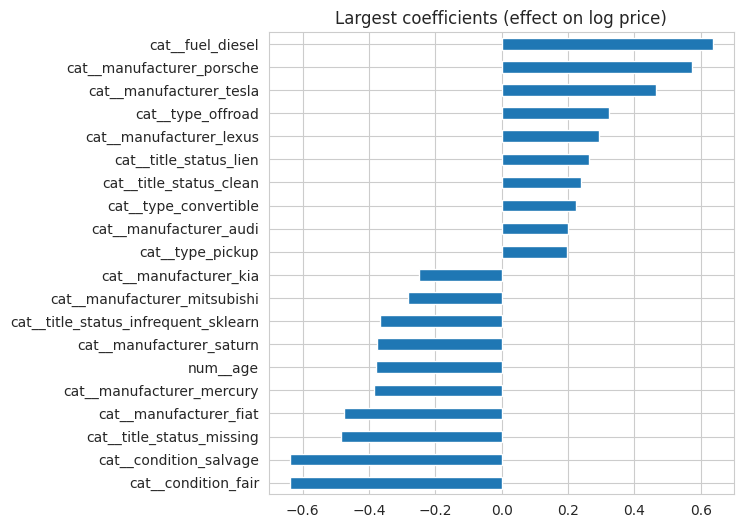

In [43]:
#What drives price: coefficients (linear models)
prep = best_model.named_steps["prep"]
coefs = pd.Series(best_model.named_steps["model"].coef_,
                  index=prep.get_feature_names_out()).sort_values()

# Biggest negative and positive effects on log(price)
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot(kind="barh", figsize=(6, 6), title="Largest coefficients (effect on log price)")
plt.show()

In [35]:
# Translate numeric features into dealer-friendly terms
scaler = prep.named_transformers_["num"].named_steps["scale"]
for i, name in enumerate(num_cols):
    per_unit = coefs[f"num__{name}"] / scaler.scale_[i]     # undo scaling
    if name == "age":
        print(f"Each extra year of age changes price by {np.expm1(per_unit)*100:.1f}%")
    elif name == "odometer":
        print(f"Each extra 10,000 miles changes price by {np.expm1(per_unit*10000)*100:.1f}%")
    else:
        print(f"Each extra cylinder changes price by {np.expm1(per_unit)*100:.1f}%")

Each extra year of age changes price by -6.3%
Each extra 10,000 miles changes price by -3.9%
Each extra cylinder changes price by 10.1%


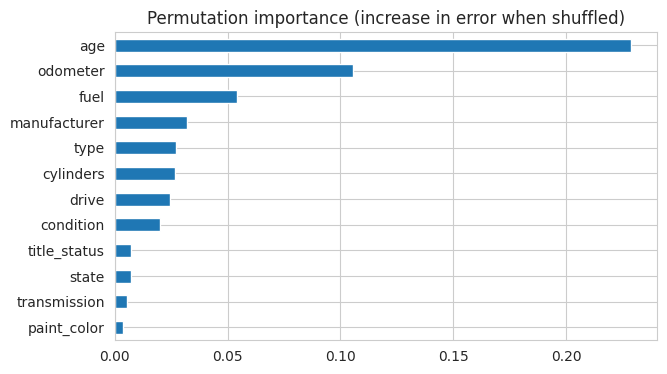

In [46]:
#What drives price: permutation importance (works on original columns)
sample = X_test.sample(20000, random_state=42)
perm = permutation_importance(best_model, sample, y_test.loc[sample.index],
                              n_repeats=3, random_state=42, n_jobs=-1,
                              scoring="neg_root_mean_squared_error")

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind="barh", figsize=(7, 4),
                title="Permutation importance (increase in error when shuffled)")
plt.show()

## Deployment: Findings for Used Car Dealers

### Summary
We analyzed about [363,000] used car listings to learn what makes a car more or less expensive. Our best model explains roughly [x]% of the differences in price, and its predictions are typically within about $[x] of the listed price. That is accurate enough to show which factors matter most, but it is not a substitute for checking local market prices on a specific car.

### What drives price

| Rank | Factor | What we found |
|---|---|---|
| 1 | **Age** | Each additional year lowers price by about 6.3% (compounding), so a 10-year-old car is worth roughly half as much as an otherwise similar new one. |
| 2 | **Mileage** | Each additional 10,000 miles lowers price by about 3.9%. |
| 3 | **Fuel type** | Diesel vehicles sell for about 89% more than comparable vehicles. |
| 4 | **Manufacturer** | Premiums: Porsche (+78%), Tesla (+59%), Lexus (+34%), Audi (+22%). Discounts: Fiat (-38%), Mercury (-32%), Saturn (-31%), Mitsubishi (-25%), Kia (-22%). |
| 5 | **Vehicle type** | Off-road (+38%), convertibles (+25%), and pickups (+22%) carry premiums. |
| 6 | **Engine size** | Each additional cylinder adds about 10% (for example, a 6-cylinder is worth about 21% more than a comparable 4-cylinder). |
| 7 | **Condition** | Cars in fair or salvage condition sell for about 47% less than comparable cars in better condition. |
| 8 | **Title status** | Matters less overall because most cars have clean titles, but a missing or rare (salvage-type) status cuts price by roughly a third. |

**Factors that matter little:** [e.g., paint color, state].

### Recommendations for inventory
1. **Favor newer, lower-mileage vehicles.** Age and mileage are the strongest price signals. [Name a sweet spot, e.g., 3 to 6 years old, under 80,000 miles, if your data supports it.]
2. **Stock the segments buyers pay a premium for.** [e.g., trucks, 4WD, specific manufacturers.]
3. **Be careful with title problems and unknown condition.** [Salvage/rebuilt titles discount heavily. Listings with no stated condition tend to price lower, so inspect and document condition to support a higher price.]
4. **Don't overpay for cosmetics.** [e.g., paint color had little effect on price.]
5. **Buy with the price curve in mind.** [e.g., price drops fastest in the first few years, so a 2 to 3 year old car may offer the best value per dollar.]

### Limitations and next steps

**Limitations**
- The typical prediction error is about $5,000, so the model shows broad price drivers, not exact prices for individual cars.
- These are **listing prices**, not final sale prices.
- The results show **association, not cause**, and reflect this one dataset, so they may differ by region or over time.
- Each effect is measured with the other factors held equal, so effects overlap in real cars (older cars usually have more miles) and should not be added together.
- Categories labeled "infrequent" combine rare values, so they cannot be read as one specific brand or title status.

**Next steps**
- Add vehicle `model` to the analysis, since make and model likely explain more of the price.
- Track days-on-lot to link price to how fast cars sell.
- Refresh the analysis regularly with new data.